# NN_L6_zipf

**Rank-frequency plot of the words of the European Central Bank speeches 2022-2026, log-log, with the fitted power law (Zipf's law).**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_zipf/NN_L6_zipf.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$f(r)\approx Cr^{-a}$, fitted by least squares on log rank and log frequency for ranks 10 to 10,000.

tokens = 1289896   [corpus.n_tokens]
distinct words = 20130   [corpus.n_types]
slope = -1.498   [corpus.zipf_slope]


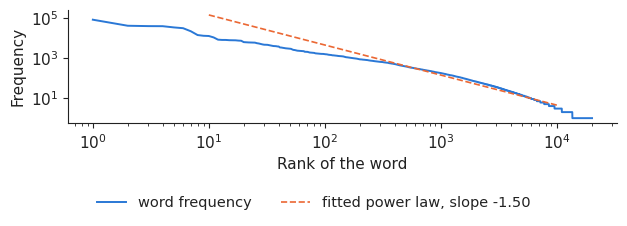

In [3]:
import re
from collections import Counter
TOK = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)*")
def tok(s):
    s = re.sub(r'https?://\S+|@\w+', ' ', str(s).lower())
    return ['<num>' if t[0].isdigit() else t for t in TOK.findall(s)]
sp = pd.read_csv(DATA + 'ecb_speeches_2022plus.csv')
cnt = Counter(w for t in sp.contents for w in tok(t))
freq = np.array(sorted(cnt.values(), reverse=True), float); rk = np.arange(1, len(freq) + 1); s = (rk >= 10) & (rk <= 10000)
a, c = np.polyfit(np.log(rk[s]), np.log(freq[s]), 1)
show('corpus.n_tokens', 'tokens', int(freq.sum())); show('corpus.n_types', 'distinct words', len(freq)); show('corpus.zipf_slope', 'slope', round(float(a), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3)); ax.loglog(rk, freq, color=PAL['data'], lw=1.4, label='word frequency')
ax.loglog(rk[s], np.exp(c) * rk[s] ** a, color=PAL['model'], lw=1.2, ls='--', label=f'fitted power law, slope {a:.2f}')
ax.set_xlabel('Rank of the word'); ax.set_ylabel('Frequency'); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('zipf.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()